In [1]:
# import the libraries needed for the analysis
import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# load the wikipedia hyperlinks collected earlier
with open("anime_links.json", "r", encoding="utf-8") as file:
    anime_links = json.load(file)

# confirm that our data loaded correctly
print("anime articles loaded:", len(anime_links))

anime articles loaded: 10


In [3]:
# create our list of anime series
anime = [
    "Sailor Moon",
    "Naruto",
    "Dragon Ball Z",
    "One Piece",
    "Bleach",
    "Pokémon",
    "Black Clover",
    "Yu Yu Hakusho",
    "Solo Leveling",
    "Kaiju No. 8"
]

# match each anime to its wikipedia article title
article_titles = {
    "Sailor Moon": "Sailor Moon",
    "Naruto": "Naruto",
    "Dragon Ball Z": "Dragon Ball Z",
    "One Piece": "One Piece",
    "Bleach": "Bleach (manga)",
    "Pokémon": "Pokémon",
    "Black Clover": "Black Clover",
    "Yu Yu Hakusho": "YuYu Hakusho",
    "Solo Leveling": "Solo Leveling",
    "Kaiju No. 8": "Kaiju No. 8"
}

# create a directed graph
G = nx.DiGraph()

# add our anime as nodes
G.add_nodes_from(anime)

# display the number of nodes
print("total anime nodes:", G.number_of_nodes())

total anime nodes: 10


In [4]:
# create an empty list for our connections
connections = []

# compare the wikipedia links for each anime
for series in anime:
    for other in anime:

        # prevent an anime from linking to itself
        if series != other:

            # check whether the article links to another selected anime
            if article_titles[other] in anime_links[series]:
                connections.append((series, other))

# add the connections to our graph
G.add_edges_from(connections)

# display our network information
print("total nodes:", G.number_of_nodes())
print("total edges:", G.number_of_edges())

total nodes: 10
total edges: 19


In [5]:
# calculate incoming and outgoing links for each anime
results = pd.DataFrame({
    "Anime": list(G.nodes()),
    "Incoming Links": [G.in_degree(node) for node in G.nodes()],
    "Outgoing Links": [G.out_degree(node) for node in G.nodes()]
})

# sort the anime by incoming links
results = results.sort_values(
    by="Incoming Links",
    ascending=False
).reset_index(drop=True)

# display the rankings
display(results)

,Anime,Incoming Links,Outgoing Links
0,Yu Yu Hakusho,4,3
1,Naruto,3,4
2,Bleach,3,1
3,One Piece,3,3
4,Black Clover,2,5
5,Dragon Ball Z,2,1
6,Sailor Moon,1,0
7,Kaiju No. 8,1,1
8,Pokémon,0,1
9,Solo Leveling,0,0


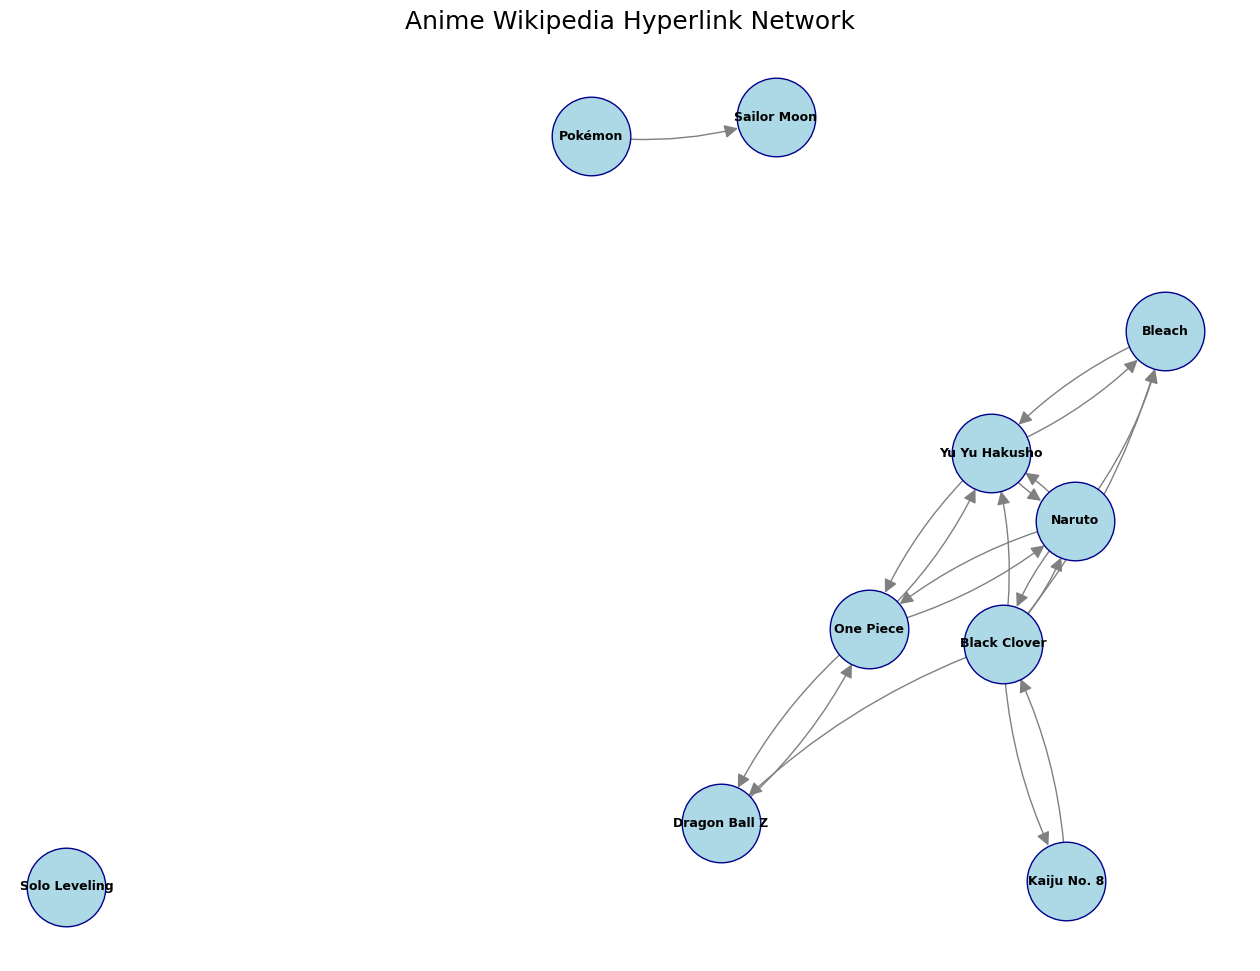

In [6]:
# create a figure for our anime network
plt.figure(figsize=(16, 12))

# calculate the positions of the nodes
positions = nx.spring_layout(G, seed=42, k=1.8, iterations=200)

# draw the nodes
nx.draw_networkx_nodes(
    G,
    positions,
    node_color="lightblue",
    node_size=3200,
    edgecolors="darkblue"
)

# draw the directed hyperlinks
nx.draw_networkx_edges(
    G,
    positions,
    edge_color="gray",
    arrows=True,
    arrowsize=20,
    node_size=3200,
    connectionstyle="arc3,rad=0.12"
)

# display the anime names
nx.draw_networkx_labels(
    G,
    positions,
    font_size=9,
    font_weight="bold"
)

# add the title and remove the axes
plt.title("Anime Wikipedia Hyperlink Network", fontsize=18)
plt.axis("off")

# save the network visualization
plt.savefig("anime_network.png", dpi=300, bbox_inches="tight")

# display the graph
plt.show()

In [7]:
# save the anime rankings to a csv file
results.to_csv("anime_results.csv", index=False)

# save the directed connections to a csv file
connections_df = pd.DataFrame(
    connections,
    columns=["Source", "Target"]
)

connections_df.to_csv("anime_connections.csv", index=False)

# check that the network data is consistent
print("total nodes:", G.number_of_nodes())
print("total edges:", G.number_of_edges())
print("total incoming links:", results["Incoming Links"].sum())
print("total outgoing links:", results["Outgoing Links"].sum())

# confirm that our files were saved
print("saved anime_results.csv")
print("saved anime_connections.csv")

total nodes: 10
total edges: 19
total incoming links: 19
total outgoing links: 19
saved anime_results.csv
saved anime_connections.csv


## Data Collection and Methodology

For this project, I wanted to see how 10 different anime are connected through their Wikipedia pages.

I used Python and the Wikipedia API to collect the links from each anime's page. I then saved the information in a JSON file so I wouldn't have to collect everything again.

Each anime is represented by a node, and the arrows show when one anime's Wikipedia page links to another. I used NetworkX to create the graph and counted the incoming and outgoing links.

I focused on incoming links to determine which anime were the most important in my network.

## Validation

My network has 10 anime and 19 connections. I checked the total incoming and outgoing links, and both added up to 19.

I also had to correct the Wikipedia pages for Bleach and Yu Yu Hakusho because the original results weren't showing the right information.

## Limitations

One limitation is that I only looked at 10 anime, so my results don't represent every anime on Wikipedia.

I also ran into some problems while collecting my data. When I searched for Bleach, Wikipedia gave me the page about the cleaning chemical instead of the anime. With Yu Yu Hakusho, I was getting information from a redirect page instead of the actual article. I had to correct both article titles to get the right information. This showed me how important it is to double-check the data instead of assuming everything is correct.

Some links might also come from Wikipedia's navigation sections instead of the main article. It's also possible that I missed some connections because of different article names or redirects.

Lastly, just because an anime has more incoming links doesn't necessarily mean it's more popular. It only means that more of the anime pages I selected link to it.